# **Fase 3 · Entrega final: auditoría y comunicación**

Cuaderno de la Entrega final (Benítez-Andrades et al., 2022, trasladado al corpus *Contextualized Hate Speech*). Parte de los resultados de la Fase 2, copiados en `insumos/`.

In [1]:
import os, sys, json, time, hashlib, subprocess, importlib.metadata as im
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from huggingface_hub import hf_hub_download
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, precision_recall_fscore_support, confusion_matrix

gpus = tf.config.list_physical_devices("GPU")
assert gpus, "TensorFlow no ve la GPU: selecciona el kernel «Python 3.12 (Fase 3 · GPU Metal)»"
print("Python:", sys.version.split()[0], "| kernel:", sys.executable)
print("GPU:", gpus)
print({p: im.version(p) for p in ("tensorflow", "tensorflow-metal", "tf-keras", "transformers", "scikit-learn")})

/Users/maria/.venvs/fase3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.14 | kernel: /Users/maria/.venvs/fase3/bin/python
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{'tensorflow': '2.18.1', 'tensorflow-metal': '1.2.0', 'tf-keras': '2.18.0', 'transformers': '4.57.6', 'scikit-learn': '1.9.1'}


In [2]:
# Datos y partición congelada de la Fase 2
INSUMOS = Path("insumos"); SALIDAS = Path("salidas"); SALIDAS.mkdir(exist_ok=True)
assert INSUMOS.is_dir(), "Abre el cuaderno desde la carpeta «fase 3»"
SEED = 42
REPO_ID = "piuba-bigdata/contextualized_hate_speech"
REVISION = "01aa9dcf5cdf81c14b412bf1b9c5e6b5fba9f98d"
config = json.load(open(INSUMOS / "configuracion_elegida.json"))

def normalizacion_minima(s):
    s = s.str.replace(r"https?://\S+", " url ", regex=True)
    s = s.str.replace(r"@\w+", " usuario ", regex=True)
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

partes = [pd.read_parquet(hf_hub_download(REPO_ID, f"data/{n}-00000-of-00001.parquet", repo_type="dataset", revision=REVISION),
                          columns=["id", "text", "RACISM"]) for n in ["train", "dev", "test"]]
todos = pd.concat(partes).drop_duplicates("id")
part = pd.read_csv(INSUMOS / "particion_local.csv").merge(todos, on="id")
tr, va, te = (part[part.particion == p] for p in ("train", "val", "test"))
y_tr, y_va, y_te = tr["RACISM"].to_numpy(), va["RACISM"].to_numpy(), te["RACISM"].to_numpy()

huella = hashlib.sha256("".join(map(str, sorted(te["id"]))).encode()).hexdigest()[:16]
assert huella == "a6919b60a4886b72", "el conjunto de prueba cambió"
datos = json.load(open(INSUMOS / "datos_local.json", encoding="utf-8"))
assert (np.array(datos["eval_y"]) == y_va).all(), "la validación no coincide con la Fase 2"
txt_te = normalizacion_minima(te["text"].reset_index(drop=True))
json.dump({"test_text": txt_te.tolist()}, open(SALIDAS / "datos_test.json", "w", encoding="utf-8"))
print(f"Prueba congelada verificada (huella {huella}): {len(te):,} tuits, {int(y_te.sum())} racistas ({100 * y_te.mean():.2f} %)")
print(f"Entrenamiento: {len(datos['train_y']):,} tuits tras el submuestreo 5:1 | validación: {len(y_va):,} tuits")

def prob_racista(lg):
    return np.exp(lg[:, 1] - np.logaddexp(lg[:, 0], lg[:, 1]))

def mejor_umbral(y, puntaje):
    p, r, t = precision_recall_curve(y, puntaje)
    f = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return float(t[np.argmax(f)])

def metricas(y, puntaje, umbral):
    pred = (puntaje >= umbral).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"F1 macro": f1_score(y, pred, average="macro"), "precisión (racista)": p[0], "recall (racista)": r[0],
            "F1 (racista)": f[0], "PR-AUC": average_precision_score(y, puntaje), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp), "umbral": umbral}

Prueba congelada verificada (huella a6919b60a4886b72): 8,175 tuits, 355 racistas (4.34 %)
Entrenamiento: 9,900 tuits tras el submuestreo 5:1 | validación: 8,202 tuits


## **8.1. Modelo final y consolidación del traslado**

### 1. Selección a partir de la comparación validada

La elección no se hace con la prueba. En 7.3 se fijó de antemano la regla: mayor **PR-AUC medio en validación** y, si la diferencia con otro nivel es menor que una desviación, el que entrena menos parámetros. Esa regla eligió **T3 (BETO uncased, ajuste completo)**. Las tablas siguientes reúnen la evidencia de la Fase 2 en los tres criterios que pide la decisión: métricas, estabilidad y costo.

In [3]:
# Métricas: mismos 8,175 tuits de prueba para todos los modelos, umbral elegido en validación
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None)
resumen_f2 = pd.read_csv(INSUMOS / "resultados_prueba_resumen.csv", index_col="modelo")
print(resumen_f2.to_string())

                               n       F1 macro precisión (racista) recall (racista)   F1 (racista)         PR-AUC IC95 % F1 macro IC95 % F1 racista
modelo                                                                                                                                              
Clase mayoritaria              1          0.489               0.000            0.000          0.000          0.043  [0.488, 0.490]    [0.000, 0.000]
TF-IDF + Reg. Logística        1          0.766               0.599            0.510          0.551          0.559  [0.743, 0.788]    [0.506, 0.594]
TF-IDF + Linear SVM            1          0.770               0.632            0.499          0.557          0.564  [0.744, 0.793]    [0.509, 0.602]
BETO T0 (extractor congelado)  3  0.723 ± 0.003       0.464 ± 0.016    0.479 ± 0.013  0.471 ± 0.005  0.450 ± 0.007  [0.703, 0.747]    [0.431, 0.517]
BETO T1 (2 últimas capas)      2  0.770 ± 0.015       0.603 ± 0.095    0.527 ± 0.024  0.560 ± 0.028  0.571

In [4]:
# Estabilidad del entrenamiento por nivel y semilla
dinamica = pd.read_csv(INSUMOS / "dinamica_entrenamiento.csv")
print(dinamica.round(3).to_string(index=False))

# Costo computacional de cada nivel
filas = []
for nivel in ("T0", "T1", "T2", "T3"):
    corridas = [json.load(open(p)) for p in sorted((INSUMOS / "corridas_finales").glob(f"{nivel}_s*.json"))]
    filas.append({"nivel": nivel, "semillas": len(corridas), "parámetros entrenables": corridas[0]["parametros_entrenables"],
                  "s por paso": np.median([c["paso_mediano_s"] for c in corridas]),
                  "minutos de entrenamiento": np.mean([c["paso_mediano_s"] * c["pasos_totales"] / 60 for c in corridas]),
                  "s de inferencia por 1,000 tuits": np.mean([c["inferencia_s_por_1000"] or np.nan for c in corridas])})
print("\n" + pd.DataFrame(filas).round(3).to_string(index=False))

nivel  semilla  épocas  mejor época  pérdida entren. (mejor época)  pérdida val. (mejor época)  pérdida val. (última época)  % pasos recortados
   T0        0      25           22                          0.245                       0.186                        0.188                 NaN
   T0        1      24           21                          0.244                       0.182                        0.189                 NaN
   T0        2      18           15                          0.254                       0.186                        0.190                 NaN
   T1        0       3            3                          0.223                       0.153                        0.153              95.907
   T1        1       2            1                          0.334                       0.119                        0.156              96.688
   T2        0       3            2                          0.233                       0.144                        0.166             

**Lectura.** Los tres criterios llevan a **T3**:

- **Métricas.** T3 obtiene el mayor F1 macro (0.803 ± 0.009) y el mayor PR-AUC (0.656 ± 0.004), frente a 0.770 y 0.564 de la SVM. T1 solo iguala a la línea base y T2 (0.781) queda por debajo de T3, con intervalos que se solapan.
- **Estabilidad.** Las tres semillas de T3 alcanzan su mejor punto en la primera época y su PR-AUC es el menos disperso. Lo inestable es el punto de operación: el recall va de 0.544 a 0.659 según la semilla, porque el umbral cambia. El recorte de gradiente se activa en el 88-90 % de los pasos, sin divergencia.
- **Costo.** T3 entrena unos 17 minutos, frente a 9 de T2, pero su inferencia es prácticamente igual (≈ 9 s por 1,000 tuits). Frente a T2, el costo adicional está solo en el entrenamiento.

La Fase 2 evaluó T3 como configuración, con tres semillas. Para tener **un único modelo que evaluar y auditar**, se elige la semilla con el mismo criterio de 7.3 (mayor PR-AUC en validación), sin usar la prueba.

In [5]:
# Elección de la semilla solo con validación
pr_auc_val = {s: average_precision_score(y_va, prob_racista(np.load(INSUMOS / "corridas_finales" / f"T3_s{s}_val_logits.npy"))) for s in (0, 1, 2)}
SEMILLA = max(pr_auc_val, key=pr_auc_val.get)
print("PR-AUC en validación por semilla:", {s: round(v, 4) for s, v in pr_auc_val.items()})
print("Semilla del modelo final:", SEMILLA)

PR-AUC en validación por semilla: {0: 0.6441, 1: 0.6526, 2: 0.6403}
Semilla del modelo final: 1


### 2. Configuración definitiva

In [6]:
config_final = {"modelo preentrenado": config["checkpoint"], "nivel": config["nivel"], "capas descongeladas": f"{config['n_desc']} de 12 + embeddings",
                "tasa del codificador": config["lr_enc"], "tasa de la cabeza": config["lr_head"], "tamaño de lote": config["lote"], "longitud máxima": config["max_len"],
                "warm-up": config["warmup"], "recorte de gradiente": config["recorte"], "máximo de épocas": config["epocas"], "paciencia": config["paciencia"],
                "submuestreo de negativos (solo entrenamiento)": "5:1", "semilla": SEMILLA}
json.dump(config_final, open(SALIDAS / "configuracion_definitiva.json", "w"), indent=1, ensure_ascii=False)
print(pd.Series(config_final).to_string())

modelo preentrenado                              dccuchile/bert-base-spanish-wwm-uncased
nivel                                                                                 T3
capas descongeladas                                                12 de 12 + embeddings
tasa del codificador                                                             0.00003
tasa de la cabeza                                                                  0.001
tamaño de lote                                                                        16
longitud máxima                                                                       64
warm-up                                                                             0.06
recorte de gradiente                                                                 1.0
máximo de épocas                                                                       3
paciencia                                                                              1
submuestreo de negati

### 3. Reentrenamiento del modelo final

La Fase 2 guardó las predicciones, pero no los pesos. Se reentrena con la misma configuración y semilla, conservando los pesos de la mejor época por pérdida de validación. 

In [7]:
etiqueta = f"T3_s{SEMILLA}"; salida = SALIDAS / etiqueta; DIR_MODELO = SALIDAS / "modelo_final"
if not (salida.with_suffix(".json").exists() and (DIR_MODELO / "tf_model.h5").exists()):
    args = {k: config[k] for k in ("checkpoint", "lote", "max_len", "warmup", "recorte", "lr_head", "lr_enc", "n_desc", "epocas", "paciencia")}
    args.update(semilla=SEMILLA, datos=str(INSUMOS / "datos_local.json"), datos_test=str(SALIDAS / "datos_test.json"), salida=str(salida), modelo=str(DIR_MODELO))
    proceso = subprocess.Popen([sys.executable, "entrenar_modelo_final.py", json.dumps(args)], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for linea in proceso.stdout:
        print(linea, end="")
    assert proceso.wait() == 0, "El entrenamiento falló; revisa el mensaje anterior"
res = json.load(open(salida.with_suffix(".json")))
val_final = prob_racista(np.load(f"{salida}_val_logits.npy")); test_final = prob_racista(np.load(f"{salida}_test_logits.npy"))
print(f"Épocas ejecutadas: {res['epocas_ejecutadas']} | mejor época: {res['mejor_epoca']} | pérdida de validación por época: {np.round(res['hist']['val_loss'], 3)}")

Dispositivos GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
I0000 00:00:1793992873.387083  674610 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793992873.387110  674610 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
All model checkpoint layers were used when initializing TFBertForSequenceClassification.

Some layers of TFBertForSequenceClassification were not initialized from the model checkpoint at dccuchile/bert-base-spanish-wwm-uncased and are newly initialized: ['classifier', 'bert/pooler/dense/bias:0', 'bert/pooler/dense/k

In [8]:
# Comprobación: los pesos guardados dan las mismas predicciones y entregan la atención que usará 8.2
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
tok_final = AutoTokenizer.from_pretrained(DIR_MODELO)
modelo_final = TFAutoModelForSequenceClassification.from_pretrained(DIR_MODELO)
enc = tok_final(datos["eval_text"][:64], padding=True, pad_to_multiple_of=16, truncation=True, max_length=config["max_len"], return_tensors="tf")
salida_mod = modelo_final(dict(enc), training=False, output_attentions=True)
dif = np.abs(salida_mod.logits.numpy() - np.load(f"{salida}_val_logits.npy")[:64]).max()
assert dif < 1e-2, f"Los pesos guardados no reproducen las predicciones (diferencia {dif:.4f})"
print(f"Diferencia máxima de logits: {dif:.6f} | capas de atención: {len(salida_mod.attentions)} | forma: {salida_mod.attentions[0].shape}")

I0000 00:00:1793995961.644586  673958 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793995961.645100  673958 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
All model checkpoint layers were used when initializing TFBertForSequenceClassification.

All the layers of TFBertForSequenceClassification were initialized from the model checkpoint at salidas/modelo_final.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertForSequenceClassification for predictions without further training.
TensorFlow and JAX c

Diferencia máxima de logits: 0.000000 | capas de atención: 12 | forma: (64, 12, 64, 64)


El reentrenamiento repite la dinámica de la Fase 2: la mejor época es la primera y la pérdida de validación sube en la segunda (0.116 → 0.160), por lo que la parada temprana conserva la época 1. Los pesos guardados reproducen exactamente las predicciones (diferencia de logits de 0) y entregan las 12 capas de atención que usará la auditoría de 8.2.

### 4. Evaluación sobre el conjunto de prueba

El umbral se elige en validación y se aplica sin cambios a la prueba congelada, una sola vez. El modelo se compara con la mejor línea base de la Fase 2 (TF-IDF + SVM lineal), reentrenada aquí para medir su costo en la misma máquina, y con la corrida original de la misma semilla, para medir la reproducibilidad.

In [9]:
# Línea base: misma configuración de 7.4 (C elegido en validación)
txt_tr, txt_va = normalizacion_minima(tr["text"]), normalizacion_minima(va["text"])
t0 = time.perf_counter()
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
svm = LinearSVC(C=1, class_weight="balanced", max_iter=20000, random_state=SEED).fit(vec.fit_transform(txt_tr), y_tr)
seg_ent_svm = time.perf_counter() - t0
val_svm = svm.decision_function(vec.transform(txt_va))
t0 = time.perf_counter(); test_svm = svm.decision_function(vec.transform(te["text"].pipe(normalizacion_minima))); seg_inf_svm = time.perf_counter() - t0

u_final, u_svm = mejor_umbral(y_va, val_final), mejor_umbral(y_va, val_svm)
por_semilla = pd.read_csv(INSUMOS / "resultados_prueba_por_semilla.csv")
f2 = por_semilla[(por_semilla.modelo == "BETO T3 (ajuste completo)") & (por_semilla.semilla == str(SEMILLA))].iloc[0]
media_t3 = por_semilla[por_semilla.modelo == "BETO T3 (ajuste completo)"]
cols = ["F1 macro", "precisión (racista)", "recall (racista)", "F1 (racista)", "PR-AUC", "TN", "FP", "FN", "TP", "umbral"]
m_final = metricas(y_te, test_final, u_final)
evaluacion = pd.DataFrame({"Modelo final (reentrenado)": m_final, f"T3 semilla {SEMILLA}, Fase 2": f2[cols].astype(float),
                           "T3 media de 3 semillas, Fase 2": media_t3[cols].astype(float).mean(),
                           "TF-IDF + SVM lineal": metricas(y_te, test_svm, u_svm)}).loc[cols]
evaluacion.to_csv(SALIDAS / "evaluacion_modelo_final.csv")
print(evaluacion.round(3).to_string())

lg_f2 = np.load(INSUMOS / "corridas_finales" / f"T3_s{SEMILLA}_test_logits.npy")
acuerdo = ((prob_racista(lg_f2) >= float(f2["umbral"])) == (test_final >= u_final)).mean()
print(f"\nReproducibilidad frente a la Fase 2: {100 * acuerdo:.2f} % de predicciones iguales | "
      f"correlación de probabilidades: {np.corrcoef(prob_racista(lg_f2), test_final)[0, 1]:.4f}")

                     Modelo final (reentrenado)  T3 semilla 1, Fase 2  T3 media de 3 semillas, Fase 2  TF-IDF + SVM lineal
F1 macro                                  0.815                 0.810                           0.803                0.770
precisión (racista)                       0.612                 0.617                           0.636                0.632
recall (racista)                          0.687                 0.659                           0.615                0.499
F1 (racista)                              0.647                 0.638                           0.623                0.557
PR-AUC                                    0.656                 0.656                           0.656                0.564
TN                                     7665.000              7675.000                        7693.667             7717.000
FP                                      155.000               145.000                         126.333              103.000
FN              

In [ ]:
# Incertidumbre (bootstrap pareado sobre la prueba) y costo frente a la línea base
pred_final, pred_svm = (test_final >= u_final).astype(int), (test_svm >= u_svm).astype(int)
def f1_rapido(y, p):
    tp = (y * p).sum(); fp = ((1 - y) * p).sum(); fn = (y * (1 - p)).sum(); tn = len(y) - tp - fp - fn
    f_pos, f_neg = 2 * tp / max(1, 2 * tp + fp + fn), 2 * tn / max(1, 2 * tn + fn + fp)
    return (f_pos + f_neg) / 2, f_pos, tp / max(1, tp + fn), tp / max(1, tp + fp)
rng = np.random.RandomState(SEED); indices = rng.randint(0, len(y_te), size=(1000, len(y_te)))
m_f = np.array([f1_rapido(y_te[i], pred_final[i]) for i in indices]); m_b = np.array([f1_rapido(y_te[i], pred_svm[i]) for i in indices])
ic = pd.DataFrame({"modelo final": m_f.mean(0), "IC95 % inf.": np.percentile(m_f, 2.5, axis=0), "IC95 % sup.": np.percentile(m_f, 97.5, axis=0),
                   "diferencia con SVM": (m_f - m_b).mean(0), "dif. IC95 % inf.": np.percentile(m_f - m_b, 2.5, axis=0), "dif. IC95 % sup.": np.percentile(m_f - m_b, 97.5, axis=0)},
                  index=["F1 macro", "F1 (racista)", "recall (racista)", "precisión (racista)"])
print(ic.round(3).to_string())

inf_svm = 1000 * seg_inf_svm / len(y_te)
costo = pd.DataFrame({"Modelo final": {"parámetros entrenables": res["parametros_entrenables"], "minutos de entrenamiento": res["minutos_totales"], "s de inferencia por 1,000 tuits": res["inferencia_s_por_1000"]},
                      "TF-IDF + SVM lineal": {"parámetros entrenables": svm.coef_.size, "minutos de entrenamiento": seg_ent_svm / 60, "s de inferencia por 1,000 tuits": inf_svm}})
print("\n" + costo.round(4).to_string())
print(f"\nInferencia del modelo final: {res['inferencia_s_por_1000'] / inf_svm:,.0f} veces más lenta que la línea base")

                     modelo final  IC95 % inf.  IC95 % sup.  diferencia con SVM  dif. IC95 % inf.  dif. IC95 % sup.
F1 macro                    0.816        0.795        0.835               0.046             0.022             0.072
F1 (racista)                0.648        0.608        0.686               0.091             0.045             0.142
recall (racista)            0.688        0.638        0.734               0.189             0.135             0.243
precisión (racista)         0.613        0.564        0.660              -0.019            -0.071             0.035

                                 Modelo final  TF-IDF + SVM lineal
parámetros entrenables           1.098524e+08           62924.0000
minutos de entrenamiento         2.983590e+01               0.0227
s de inferencia por 1,000 tuits  9.690900e+00               0.0161

Inferencia del modelo final: 600 veces más lenta que la línea base


- **Modelo final.** Sobre la prueba obtiene F1 macro de 0.815 (IC 95 %: 0.795-0.835), F1 de la clase racista de 0.647, recall de 0.687 y precisión de 0.612. Detecta 244 de los 355 mensajes racistas, con 155 falsos positivos. Es una sola corrida y queda por encima de la media de la configuración, de modo que el rendimiento esperable de T3 se sigue describiendo con 0.803 ± 0.009.
- **Frente a la línea base.** Mejora el F1 macro en 0.046 [0.022, 0.072], el F1 de la clase racista en 0.091 [0.045, 0.142] y el recall en 0.189 [0.135, 0.243]. La diferencia en precisión (−0.019 [−0.071, 0.035]) es indistinguible de cero. La mejora proviene del recall.
- **Reproducibilidad.** Con la misma configuración y semilla, el resultado es equivalente pero no idéntico: coincide el 99.41 % de las predicciones y la correlación de probabilidades es de 0.976. El PR-AUC se mantiene (0.656), pero el umbral pasa de 0.645 a 0.703 y el recall de 0.659 a 0.687. El ordenamiento es estable; el punto de operación es la parte frágil.
- **Costo.** El modelo final tardó 29.8 minutos en GPU, incluidas la validación, la predicción y el guardado, y tiene ≈ 110 millones de parámetros. La SVM entrena en ≈ 1.4 s con 62,924 coeficientes. La inferencia es ≈ 600 veces más lenta (9.69 s frente a 0.016 s por 1,000 tuits); en la Fase 2 la razón fue ≈ 900, porque estos tiempos tan pequeños varían entre ejecuciones. El orden de magnitud se mantiene.

### 5. Contraste con el artículo

| Aspecto | Artículo (Benítez-Andrades et al., 2022) | Traslado local | Qué pasó |
|---|---|---|---|
| Arquitectura | BETO uncased | BETO uncased, con *fine-tuning* completo | **Se conservó** |
| Tarea | Clasificación binaria: racista o no | Clasificación binaria: `RACISM` | **Se conservó** |
| Corpus | 2,000 tuits en español, recolectados con palabras clave | 54,442 respuestas a cinco medios argentinos | **Cambió** |
| Prevalencia | 48.6 % de positivos | 4.3 % de positivos | **Cambió** |
| Preparación del texto | `clean_tweet` | Normalización mínima | **Cambió** |
| Partición | 70/30 aleatoria, sin estratificar | 70/15/15 estratificada y agrupada por noticia | **Cambió** |
| Entrenamiento | 8 épocas fijas, lote 8, longitud 128 | Hasta 3 épocas con parada, lote 16, longitud 64, tasas diferenciadas | **Cambió** |
| Decisión | Umbral implícito de 0.5 | Umbral elegido en validación | **Cambió** |



In [11]:
# Artículo: Tabla 5 y Figura 6 (BETO) | Réplica de la Fase 2: BETO uncased, 3 semillas
TN_A, FP_A, FN_A, TP_A = 268, 39, 50, 243
bert_rep = pd.read_csv(INSUMOS / "resultados_bert.csv")
rep = bert_rep[bert_rep.modelo == "BETO uncased | 8 épocas (Tabla 3)"]
rep_cm = rep[["TN", "FP", "FN", "TP"]].mean()
PREV_ART, PREV_LOCAL = (TP_A + FN_A) / (TN_A + FP_A + FN_A + TP_A), float(y_te.mean())

def fila(f1_macro, tn, fp, fn, tp, f1_rac=None):
    tpr, fpr = tp / (tp + fn), fp / (fp + tn)
    prec = lambda pi: tpr * pi / (tpr * pi + fpr * (1 - pi))
    return {"F1 macro": f1_macro, "F1 macro de un predictor constante": None, "prevalencia": (tp + fn) / (tn + fp + fn + tp),
            "F1 racista": f1_rac if f1_rac is not None else 2 * tp / (2 * tp + fp + fn), "recall racista": tpr, "tasa de falsos positivos": fpr,
            "precisión observada": tp / (tp + fp), f"precisión con prevalencia {100 * PREV_ART:.1f} %": prec(PREV_ART), f"precisión con prevalencia {100 * PREV_LOCAL:.2f} %": prec(PREV_LOCAL)}

def f1_constante(tn, fp, fn, tp):
    negativos, positivos = tn + fp, fn + tp
    return negativos / (2 * negativos + positivos) if negativos > positivos else positivos / (2 * positivos + negativos)

contraste = pd.DataFrame({"Artículo": fila(0.8514, TN_A, FP_A, FN_A, TP_A, 0.8452),
                          "Réplica (Fase 2)": fila(rep["F1_macro"].mean() / 100, *rep_cm),
                          "Modelo final local": fila(m_final["F1 macro"], m_final["TN"], m_final["FP"], m_final["FN"], m_final["TP"])})
contraste.loc["F1 macro de un predictor constante"] = [f1_constante(TN_A, FP_A, FN_A, TP_A), f1_constante(*rep_cm), f1_constante(m_final["TN"], m_final["FP"], m_final["FN"], m_final["TP"])]
contraste.to_csv(SALIDAS / "contraste_articulo.csv")
print(contraste.astype(float).round(3).to_string())

                                    Artículo  Réplica (Fase 2)  Modelo final local
F1 macro                               0.851             0.831               0.815
F1 macro de un predictor constante     0.338             0.338               0.489
prevalencia                            0.488             0.488               0.043
F1 racista                             0.845             0.823               0.647
recall racista                         0.829             0.807               0.687
tasa de falsos positivos               0.127             0.145               0.020
precisión observada                    0.862             0.841               0.612
precisión con prevalencia 48.8 %       0.862             0.841               0.971
precisión con prevalencia 4.34 %       0.229             0.201               0.612


**Lectura.**

- **Qué se conservó.** La arquitectura y el flujo funcionan fuera del corpus original: la réplica alcanzó un F1 macro de 0.831 frente a 0.851 del artículo, y el modelo trasladado aprende la tarea local y supera a la línea base.
- **Qué cambió.** El F1 macro baja de 0.851 a 0.815, pero la comparación directa favorece al corpus local, porque un predictor constante ya obtiene allí 0.489 (0.338 en el artículo). El F1 de la clase racista baja de 0.845 a 0.647 y el recall de 0.829 a 0.687, mientras que la tasa de falsos positivos cae de 0.127 a 0.020.
- **Qué lo explica.** (a) **Prevalencia, con evidencia directa:** con los mismos recall y tasa de falsos positivos, la precisión del artículo bajaría de 0.862 a 0.229 con una prevalencia de 4.34 %. Este cálculo muestra el efecto de la prevalencia y no que el modelo local sea mejor, porque los corpus, las etiquetas y los puntos de operación son distintos. (b) **Punto de operación:** el umbral elegido en validación busca el mejor F1 de una clase escasa, lo que cambia el equilibrio entre recall y falsos positivos. (c) **Hipótesis por comprobar en 8.2 y 8.3:** el corpus del artículo se recolectó con palabras clave y tiene textos repetidos entre entrenamiento y prueba, mientras que la partición local se agrupa por noticia; además, la etiqueta `RACISM` es más amplia y distinta de la del artículo.


## **8.2. Auditoría del modelo mediante explicabilidad**

Se audita el modelo final de 8.1 con las **matrices de atención** de sus 12 capas. Como la atención por sí sola no garantiza una explicación (Jain & Wallace, 2019), la lectura se apoya en tres evidencias:

1. **Atención.** La matriz de la última capa y el *attention rollout* (Abnar & Zuidema, 2020), que combina las 12 capas en la atención efectiva desde `[CLS]`, el token con el que el modelo clasifica, hacia cada palabra.
2. **Fidelidad.** Si al borrar las palabras más atendidas la probabilidad cae más que al borrar palabras al azar, la atención señala lo que el modelo usa para decidir.
3. **Casos de prueba de respuesta conocida**, construidos por el equipo (Ribeiro et al., 2020; Röttger et al., 2021).

Atajos que se revisan: las marcas `usuario` y `url` que deja la normalización (marcas del origen de los datos), la mención de una nacionalidad sin contenido racista (correlación espuria; Dixon et al., 2018), los tokens especiales y la puntuación.

In [ ]:
# Modelo final y extracción de la atención (si el kernel se reinició, se recarga desde disco)
import unicodedata
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction.text import CountVectorizer
from transformers import AutoTokenizer, TFAutoModelForSequenceClassification
if "modelo_final" not in globals():
    tok_final = AutoTokenizer.from_pretrained(DIR_MODELO)
    modelo_final = TFAutoModelForSequenceClassification.from_pretrained(DIR_MODELO)
MAX_LEN, U = config["max_len"], u_final

def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFD", s.lower()) if unicodedata.category(c) != "Mn")

def analizar(textos, lote=32, matrices=False):
    """Para cada texto: probabilidad de racismo y atención desde [CLS] hacia cada palabra (rollout de las 12 capas y última capa)."""
    salida = []
    for i in range(0, len(textos), lote):
        bloque = list(textos[i:i + lote])
        enc = tok_final(bloque, padding=True, truncation=True, max_length=MAX_LEN, return_offsets_mapping=True, return_tensors="np")
        offsets = enc.pop("offset_mapping")
        r = modelo_final({k: tf.constant(v) for k, v in enc.items()}, training=False, output_attentions=True)
        prob = prob_racista(r.logits.numpy())
        A = np.stack([a.numpy().mean(axis=1) for a in r.attentions], axis=1)       # (lote, capa, L, L): promedio de las 12 cabezas
        n = A.shape[-1]; I = np.eye(n)
        roll = np.repeat(I[None], len(bloque), axis=0)
        with np.errstate(all="ignore"):                                            # evita avisos espurios de matmul en macOS
            for capa in range(A.shape[1]):                                         # rollout = A12 ··· A1, con la conexión residual
                Ac = 0.5 * A[:, capa] + 0.5 * I
                roll = (Ac / Ac.sum(-1, keepdims=True)) @ roll
        assert np.isfinite(roll).all() and np.isfinite(A).all(), "la atención tiene valores no finitos"
        for j, texto in enumerate(bloque):
            palabras = {}
            for k, w in enumerate(enc.word_ids(j)):
                if w is None:
                    continue
                s, e = offsets[j][k]
                p = palabras.setdefault(w, {"inicio": int(s), "fin": int(e), "rollout": 0.0, "ultima": 0.0})
                p["fin"] = int(e); p["rollout"] += float(roll[j, 0, k]); p["ultima"] += float(A[j, -1, 0, k])
            lista = [dict(p, palabra=texto[p["inicio"]:p["fin"]]) for _, p in sorted(palabras.items())]
            fila = {"prob": float(prob[j]), "palabras": lista, "especiales": 1 - sum(p["rollout"] for p in lista), "especiales_ultima": 1 - sum(p["ultima"] for p in lista)}
            if matrices:
                m = enc["attention_mask"][j].astype(bool)
                fila["matriz"] = A[j, -1][np.ix_(m, m)]; fila["tokens"] = tok_final.convert_ids_to_tokens(enc["input_ids"][j][m])
            salida.append(fila)
    return salida

def predecir_prob(textos, lote=64):
    out = []
    for i in range(0, len(textos), lote):
        enc = tok_final(list(textos[i:i + lote]), padding=True, truncation=True, max_length=MAX_LEN, return_tensors="tf")
        out.append(prob_racista(modelo_final(dict(enc), training=False).logits.numpy()))
    return np.concatenate(out)

### 1. Atención en el conjunto de prueba

Se calcula la atención de los 8,175 tuits de prueba y se define un léxico de referencia. Los grupos (verdaderos positivos, falsos negativos, falsos positivos y verdaderos negativos) son los de 8.1, con el umbral elegido en validación.

In [ ]:
t0 = time.perf_counter()
aud = analizar(txt_te.tolist())
prob_aud = np.array([a["prob"] for a in aud])
grupo = np.select([(y_te == 1) & (test_final >= U), (y_te == 1) & (test_final < U), (y_te == 0) & (test_final >= U)], ["VP", "FN", "FP"], "VN")
print(f"{len(aud):,} tuits en {time.perf_counter() - t0:.0f} s | diferencia máxima con las probabilidades de 8.1: {np.abs(prob_aud - test_final).max():.4f}")
print(pd.Series(grupo).value_counts().reindex(["VP", "FN", "FP", "VN"]).to_string())

8,175 tuits en 73 s | diferencia máxima con las probabilidades de 8.1: 0.0000
VP     244
FN     111
FP     155
VN    7665


In [ ]:
# Léxico de referencia: palabras asociadas con la clase racista, calculadas solo con el entrenamiento
cv = CountVectorizer(preprocessor=sin_tildes, token_pattern=r"(?u)\b[^\W\d_]{3,}\b", binary=True, min_df=20)
X = cv.fit_transform(txt_tr); voc = np.array(cv.get_feature_names_out())
pos, neg = np.asarray(X[y_tr == 1].sum(0)).ravel(), np.asarray(X[y_tr == 0].sum(0)).ravel()
log_razon = np.log((pos + 1) / ((y_tr == 1).sum() + 2)) - np.log((neg + 1) / ((y_tr == 0).sum() + 2))
orden_lex = np.argsort(-log_razon); LEXICO = set(voc[orden_lex[:100]])
print("Las 30 palabras más asociadas con la clase racista:", ", ".join(voc[orden_lex[:30]]))

TIPOS = ["tokens especiales", "marcas usuario/url", "puntuación y emojis", "léxico racista", "otras palabras"]
def tipo(palabra):
    w = sin_tildes(palabra)
    if w in ("usuario", "url"): return "marcas usuario/url"
    if not any(c.isalnum() for c in w): return "puntuación y emojis"
    return "léxico racista" if w in LEXICO else "otras palabras"

Las 30 palabras más asociadas con la clase racista: negros, sucios, chileno, chinos, negra, bolivianos, raza, negro, chilenos, putos, malditos, inglaterra, desaparecer, crearon, eliminar, extranjeros, humanidad, planeta, paraguayos, chino, comen, danos, mapuches, peste, coman, bomba, terminan, plaga, comiendo, cierren


### 2. Fidelidad de la atención

En los verdaderos positivos se borran las *k* palabras con más atención (*k* = 1 y 3), según el rollout y según la última capa, y como control *k* palabras al azar (5 sorteos por tuit). Si la atención es fiel, borrar las más atendidas debe bajar más la probabilidad y sacar más tuits de la clase racista. Como referencia independiente de la atención, la **oclusión** borra cada palabra por separado e identifica la que más baja la probabilidad.

In [ ]:
rng_b = np.random.RandomState(SEED)
def sin_palabras(a, borrar):
    return " ".join(p["palabra"] for k, p in enumerate(a["palabras"]) if k not in borrar)

vp = [i for i in np.where(grupo == "VP")[0] if len(aud[i]["palabras"]) >= 6]
variantes = {v: [] for v in ["sin borrar", "k = 1, rollout", "k = 1, última capa", "k = 1, al azar", "k = 3, rollout", "k = 3, última capa", "k = 3, al azar"]}
for i in vp:
    a = aud[i]; n = len(a["palabras"])
    top = {"rollout": np.argsort([-p["rollout"] for p in a["palabras"]]), "última capa": np.argsort([-p["ultima"] for p in a["palabras"]])}
    variantes["sin borrar"].append([sin_palabras(a, set())])
    for k in (1, 3):
        for fuente, orden_w in top.items():
            variantes[f"k = {k}, {fuente}"].append([sin_palabras(a, set(orden_w[:k]))])
        variantes[f"k = {k}, al azar"].append([sin_palabras(a, set(rng_b.choice(n, k, replace=False))) for _ in range(5)])
filas, base = [], None
for nombre, grupos_txt in variantes.items():
    p = predecir_prob([t for g in grupos_txt for t in g]).reshape(len(grupos_txt), -1)
    media_tuit = p.mean(1)
    base = media_tuit if nombre == "sin borrar" else base
    filas.append({"variante": nombre, "probabilidad media": media_tuit.mean(), "caída media": (base - media_tuit).mean(),
                  "% sigue como racista": 100 * (p >= U).mean()})
fidelidad = pd.DataFrame(filas).set_index("variante")
fidelidad.to_csv(SALIDAS / "fidelidad_atencion.csv")
print(f"Verdaderos positivos con al menos 6 palabras: {len(vp)}")
print(fidelidad.round(3).to_string())

Verdaderos positivos con al menos 6 palabras: 218
                    probabilidad media  caída media  % sigue como racista
variante                                                                 
sin borrar                       0.923        0.000               100.000
k = 1, rollout                   0.871        0.052                93.119
k = 1, última capa               0.575        0.348                56.881
k = 1, al azar                   0.867        0.056                91.376
k = 3, rollout                   0.720        0.203                72.477
k = 3, última capa               0.225        0.698                17.431
k = 3, al azar                   0.744        0.179                76.147


In [ ]:
# Oclusión: qué palabra, al borrarla sola, más baja la probabilidad
textos_o, duenos = [], []
for j, i in enumerate(vp):
    for k in range(len(aud[i]["palabras"])):
        textos_o.append(sin_palabras(aud[i], {k})); duenos.append((j, k))
p_o = predecir_prob(textos_o)
caidas = {}
for (j, k), p in zip(duenos, p_o):
    caidas.setdefault(j, {})[k] = base[j] - p
filas = []
for j, i in enumerate(vp):
    pal = aud[i]["palabras"]; k_max = max(caidas[j], key=caidas[j].get)
    filas.append({"palabra": sin_tildes(pal[k_max]["palabra"]), "tipo": tipo(pal[k_max]["palabra"]), "caída": caidas[j][k_max],
                  "coincide con rollout": k_max == int(np.argmax([p["rollout"] for p in pal])),
                  "coincide con última capa": k_max == int(np.argmax([p["ultima"] for p in pal])), "azar": 1 / len(pal)})
oclusion = pd.DataFrame(filas)
oclusion.to_csv(SALIDAS / "oclusion_verdaderos_positivos.csv", index=False)
print(f"La palabra decisiva por oclusión coincide con la más atendida: rollout {100 * oclusion['coincide con rollout'].mean():.1f} % | "
      f"última capa {100 * oclusion['coincide con última capa'].mean():.1f} % | esperado al azar {100 * oclusion['azar'].mean():.1f} %")
print(f"Caída media de probabilidad al borrar la palabra decisiva: {oclusion['caída'].mean():.3f}")
print("\nTipo de la palabra decisiva (%):"); print((100 * oclusion["tipo"].value_counts(normalize=True)).round(1).to_string())
print("\nPalabras decisivas más frecuentes:"); print(oclusion["palabra"].value_counts().head(15).to_string())

La palabra decisiva por oclusión coincide con la más atendida: rollout 7.8 % | última capa 47.2 % | esperado al azar 7.4 %
Caída media de probabilidad al borrar la palabra decisiva: 0.605

Tipo de la palabra decisiva (%):
tipo
léxico racista        73.4
otras palabras        26.1
marcas usuario/url     0.5

Palabras decisivas más frecuentes:
palabra
chinos         81
bolivianos     14
negra          12
chino          11
negros         10
china           8
boliviano       8
negro           8
bolitas         6
extranjeros     4
mugrientos      3
paraguayos      2
salvajes        2
amarillos       2
negrita         2


**Lectura.** Solo la atención de la última capa es fiel. Al borrar sus tres palabras más atendidas, el 17.4 % de los 218 verdaderos positivos sigue como racista, frente al 76.1 % cuando se borran tres al azar; con el rollout queda el 72.5 %, prácticamente igual que el azar. La oclusión lo confirma: la palabra decisiva coincide con la más atendida de la última capa en el 47.2 % de los casos (7.4 % esperado al azar) y con la del rollout solo en el 7.8 %. Por eso, el resto de la sección usa la última capa. La palabra decisiva pertenece al léxico racista en el 73.4 % de los casos y casi siempre es un gentilicio o un término racial: «chinos» decide 81 de los 218.

### 3. ¿Señal o atajos? Atención por tipo de token

Cada palabra se asigna a un tipo: tokens especiales (`[CLS]` y `[SEP]`), marcas `usuario` y `url`, puntuación y emojis, **léxico racista** (las 100 palabras más asociadas con la clase racista en el entrenamiento, por razón de frecuencias suavizada y con al menos 20 apariciones) y otras palabras. Se usa la atención que resultó fiel en la sección 2 y, como comparación, el rollout. Si el modelo usa la señal pertinente, en los verdaderos positivos la atención debería concentrarse en el léxico racista y no en las marcas ni en la puntuación.

In [ ]:
tablas_tipo = {}
for fuente, clave, especial in (("última capa", "ultima", "especiales_ultima"), ("rollout", "rollout", "especiales")):
    filas = []
    for a, g in zip(aud, grupo):
        d = {"grupo": g, "tokens especiales": a[especial], **{t: 0.0 for t in TIPOS[1:]}}
        tipos = [tipo(p["palabra"]) for p in a["palabras"]]
        for p, t in zip(a["palabras"], tipos):
            d[t] += p[clave]
        d["% palabras de léxico"] = tipos.count("léxico racista") / max(1, len(tipos))
        d["tiene léxico"] = "léxico racista" in tipos
        d["la más atendida es léxico"] = (tipos[int(np.argmax([p[clave] for p in a["palabras"]]))] == "léxico racista") if d["tiene léxico"] else np.nan
        filas.append(d)
    cat = pd.DataFrame(filas)
    t_ = cat.groupby("grupo")[TIPOS + ["% palabras de léxico", "tiene léxico", "la más atendida es léxico"]].mean().loc[["VP", "FN", "FP", "VN"]]
    t_.insert(0, "n", cat.groupby("grupo").size()); tablas_tipo[fuente] = t_
    print(f"\nAtención desde [CLS] por tipo de token ({fuente}); «la más atendida es léxico» se calcula solo en los tuits con léxico")
    print(t_.round(3).to_string())
pd.concat(tablas_tipo, names=["fuente"]).to_csv(SALIDAS / "atencion_por_tipo.csv")


Atención desde [CLS] por tipo de token (última capa); «la más atendida es léxico» se calcula solo en los tuits con léxico
          n  tokens especiales  marcas usuario/url  puntuación y emojis  léxico racista  otras palabras  % palabras de léxico  tiene léxico la más atendida es léxico
grupo                                                                                                                                                                
VP      244              0.276               0.066                0.067           0.138           0.452                 0.120         0.857                  0.416268
FN      111              0.367               0.048                0.087           0.040           0.458                 0.044         0.450                      0.24
FP      155              0.279               0.048                0.072           0.124           0.477                 0.084         0.806                     0.504
VN     7665              0.401               0.

**Lectura.** En la última capa, el léxico racista recibe 0.138 de la atención en los verdaderos positivos y 0.006 en los verdaderos negativos. En los falsos positivos recibe 0.124, casi lo mismo que en los aciertos, y en los falsos negativos solo 0.040, porque apenas el 45 % de ellos contiene ese léxico (frente al 86 % de los verdaderos positivos). El modelo responde a la presencia del léxico: lo marca cuando aparece, aunque el mensaje no sea racista, y falla cuando el racismo no usa esas palabras. Las marcas `usuario` y `url` reciben 0.066 de la atención en los verdaderos positivos, pero deciden solo el 0.5 % de los casos por oclusión. Los tokens especiales concentran entre 0.276 y 0.401 de la atención, y menos en los tuits que el modelo marca como racistas.

### 4. Ejemplos: matriz de atención y atención por palabra

Se muestran tres casos de prueba elegidos con una regla fija (entre 6 y 18 palabras, el de mayor probabilidad de su grupo): un verdadero positivo, el falso negativo más cercano al umbral y el falso positivo con mayor probabilidad.

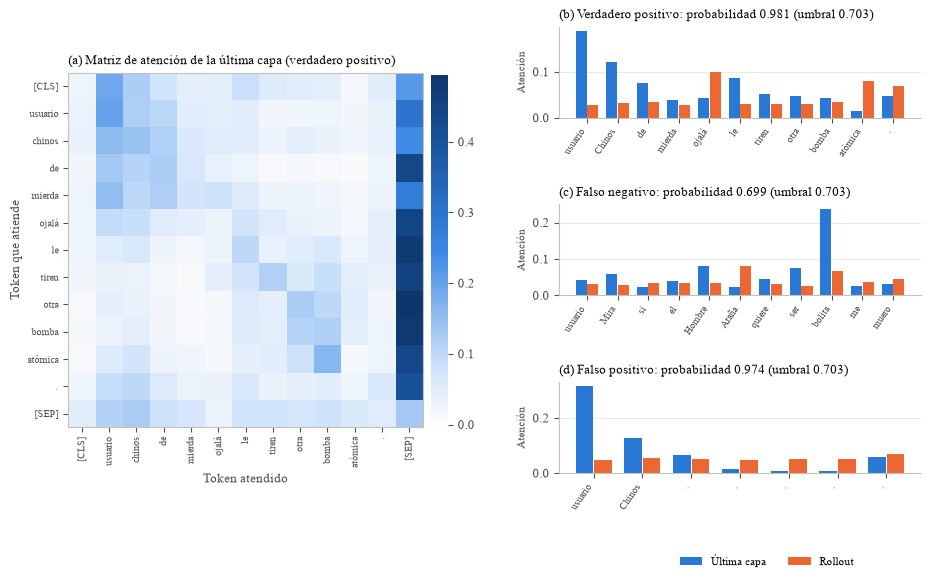

Verdadero positivo: usuario Chinos de mierda ojalá le tiren otra bomba atómica.
Falso negativo: usuario Mira si el Hombre Araña quiere ser bolita me muero
Falso positivo: usuario Chinos.....


In [ ]:
AZUL = LinearSegmentedColormap.from_list("azul", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
BARRA, NARANJA, TINTA, TENUE, REJILLA = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "font.size": 9,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TENUE, "xtick.color": TENUE, "ytick.color": TENUE})

def elegir(g):
    candidatos = [i for i in np.where(grupo == g)[0] if 6 <= len(aud[i]["palabras"]) <= 18]
    return max(candidatos, key=lambda i: test_final[i])
ejemplos = {"Verdadero positivo": elegir("VP"), "Falso negativo": elegir("FN"), "Falso positivo": elegir("FP")}
det = analizar([txt_te.iloc[ejemplos["Verdadero positivo"]]], matrices=True)[0]

fig = plt.figure(figsize=(11, 5.8)); gs = fig.add_gridspec(3, 2, width_ratios=[1.05, 1], wspace=0.3, hspace=0.95)
ax = fig.add_subplot(gs[:, 0]); im = ax.imshow(det["matriz"], cmap=AZUL, vmin=0)
ax.set_xticks(range(len(det["tokens"])), det["tokens"], rotation=90, fontsize=7); ax.set_yticks(range(len(det["tokens"])), det["tokens"], fontsize=7)
ax.set_title("(a) Matriz de atención de la última capa (verdadero positivo)", fontsize=9, loc="left", color=TINTA)
ax.set_xlabel("Token atendido"); ax.set_ylabel("Token que atiende")
barra_color = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02); barra_color.outline.set_visible(False)
for k, (nombre, i) in enumerate(ejemplos.items()):
    a = fig.add_subplot(gs[k, 1]); pal = aud[i]["palabras"]
    x = np.arange(len(pal))
    a.bar(x - 0.19, [p["ultima"] for p in pal], color=BARRA, width=0.36, label="Última capa")
    a.bar(x + 0.19, [p["rollout"] for p in pal], color=NARANJA, width=0.36, label="Rollout")
    a.set_xticks(range(len(pal)), [p["palabra"] for p in pal], rotation=55, ha="right", fontsize=7)
    a.set_title(f"({'bcd'[k]}) {nombre}: probabilidad {test_final[i]:.3f} (umbral {U:.3f})", fontsize=9, loc="left", color=TINTA)
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", color=REJILLA, linewidth=0.6); a.set_axisbelow(True)
    a.set_ylabel("Atención", fontsize=8)
fig.legend(*a.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.76, -0.07), ncol=2, frameon=False, fontsize=8)
fig.savefig(SALIDAS / "fig_atencion_ejemplos.png", dpi=200, bbox_inches="tight"); plt.show()
for nombre, i in ejemplos.items():
    print(f"{nombre}: {txt_te.iloc[i]}")

**Lectura.** En el verdadero positivo (probabilidad 0.981), la atención de la última capa se concentra en «usuario» y «Chinos», no en la amenaza («bomba atómica»). El falso positivo («usuario Chinos.....», 0.974) no contiene más que la mención del grupo y, aun así, recibe una probabilidad casi máxima. El falso negativo concentra la atención en «bolita», un término despectivo para las personas bolivianas, y queda justo debajo del umbral (0.699 frente a 0.703). El rollout reparte la atención de forma casi uniforme y no distingue esas palabras.

### 5. Casos de prueba de respuesta conocida

El equipo construyó frases con la respuesta esperada: racismo explícito (1), mención neutral de una nacionalidad (0), contradiscurso que menciona el estereotipo para rechazarlo (0) e insultos sin grupo (0). Cada plantilla se completa con seis nacionalidades frecuentes en la migración hacia Argentina y con «argentinos» como control. Las menciones neutrales se repiten con las marcas `usuario` y `url`, que no deberían cambiar la predicción. Las frases se escriben en minúscula porque el modelo es *uncased*.

In [ ]:
GRUPOS = ["bolivianos", "paraguayos", "peruanos", "venezolanos", "colombianos", "chinos", "argentinos"]
PLANTILLAS = {
    "racismo explícito": (1, ["los {g} son una plaga, que se vuelvan a su país", "hay que echar a todos los {g}, vienen a robar y a vivir de planes",
                              "los {g} son todos sucios y delincuentes"]),
    "mención neutral": (0, ["los {g} que viven en mi barrio organizaron una feria de comida", "este año llegaron muchos turistas {g} a la ciudad",
                            "los {g} ganaron el partido de anoche"]),
    "contradiscurso": (0, ["decir que los {g} son delincuentes es puro racismo", "no todos los {g} vienen a robar, basta de discriminar"]),
}
INSULTOS = ["sos un inútil, no servís para nada", "qué gobierno de porquería, son todos unos chorros", "este periodista es un ignorante"]
filas = [{"tipo": t, "esperado": e, "grupo": g, "plantilla": p, "texto": p.format(g=g)} for t, (e, ps) in PLANTILLAS.items() for p in ps for g in GRUPOS]
filas += [{"tipo": "mención neutral con usuario/url", "esperado": 0, "grupo": g, "plantilla": p, "texto": f"usuario {p.format(g=g)} url"}
          for p in PLANTILLAS["mención neutral"][1] for g in GRUPOS]
filas += [{"tipo": "insulto sin grupo", "esperado": 0, "grupo": "—", "plantilla": p, "texto": p} for p in INSULTOS]
casos = pd.DataFrame(filas)
res_c = analizar(casos["texto"].tolist())
casos["prob"] = [r["prob"] for r in res_c]; casos["predice racista"] = casos["prob"] >= U
casos["acierta"] = casos["predice racista"].astype(int) == casos["esperado"]
casos["atención al grupo"] = [sum(p["ultima"] for p in r["palabras"] if sin_tildes(p["palabra"]) == g) for r, g in zip(res_c, casos["grupo"])]
casos.to_csv(SALIDAS / "casos_de_prueba.csv", index=False)

orden_t = ["racismo explícito", "mención neutral", "mención neutral con usuario/url", "contradiscurso", "insulto sin grupo"]
resumen_c = casos.groupby("tipo").agg(n=("texto", "size"), esperado=("esperado", "first"), aciertos_pct=("acierta", "mean"),
                                       prob_media=("prob", "mean"), atencion_al_grupo=("atención al grupo", "mean")).loc[orden_t]
resumen_c["aciertos_pct"] *= 100
print(f"Umbral del modelo final: {U:.3f}\n")
print(resumen_c.round(3).to_string())
print("\n% clasificado como racista por tipo y nacionalidad")
print((100 * casos[casos.grupo != "—"].pivot_table(index="tipo", columns="grupo", values="predice racista", aggfunc="mean")).loc[orden_t[:4], GRUPOS].round(0).to_string())
neutral = casos[casos.tipo == "mención neutral"].set_index(["plantilla", "grupo"])["prob"]
marcas = casos[casos.tipo == "mención neutral con usuario/url"].set_index(["plantilla", "grupo"])["prob"]
print(f"\nEfecto de agregar «usuario» y «url» a las menciones neutrales: cambio medio de probabilidad {(marcas - neutral).mean():+.3f} "
      f"(máximo {(marcas - neutral).abs().max():.3f})")
print("\nFrases clasificadas al revés de lo esperado:")
print(casos.loc[~casos["acierta"], ["tipo", "texto", "prob"]].round(3).to_string(index=False))

Umbral del modelo final: 0.703

                                  n  esperado  aciertos_pct  prob_media  atencion_al_grupo
tipo                                                                                      
racismo explícito                21         1        95.238       0.945              0.157
mención neutral                  21         0        28.571       0.710              0.175
mención neutral con usuario/url  21         0        38.095       0.648              0.164
contradiscurso                   14         0         7.143       0.864              0.195
insulto sin grupo                 3         0       100.000       0.007              0.000

% clasificado como racista por tipo y nacionalidad
grupo                            bolivianos  paraguayos  peruanos  venezolanos  colombianos  chinos  argentinos
tipo                                                                                                           
racismo explícito                     100.0       100.0

**Lectura.** Los casos de prueba confirman el atajo. El modelo acierta el 95.2 % del racismo explícito y todos los insultos sin grupo, pero clasifica como racistas el 71.4 % de las menciones neutrales y el 92.9 % del contradiscurso. El control lo explica: con «argentinos», ninguna mención neutral se clasifica como racista, mientras que con las otras seis nacionalidades se clasifica entre el 67 % y el 100 %. Agregar `usuario` y `url` no sube la probabilidad (−0.062 en promedio), de modo que esas marcas no son un atajo. El único racismo explícito que el modelo no detecta es el dirigido a «argentinos» (0.619).

**Conclusión de 8.2.** El modelo detecta bien el racismo explícito, pero se apoya en un atajo: la mención de una nacionalidad o de un grupo racial. Lo muestran tres evidencias: la atención fiel de la última capa y la oclusión señalan los gentilicios como palabras decisivas; el modelo marca el léxico aunque el mensaje no sea racista; y los casos neutrales y de contradiscurso se clasifican como racistas, salvo con «argentinos». El modelo aprendió quién es mencionado más que qué se dice de él. La hipótesis sobre la causa (en el corpus, esas menciones coinciden casi siempre con la etiqueta racista) se examina en 8.3. **Límites:** 80 frases construidas por el equipo, un solo modelo auditado y fidelidad medida solo en los verdaderos positivos.

## **8.3. Análisis de fallas**

Se examinan los 111 falsos negativos y los 155 falsos positivos del modelo final en la prueba: qué tienen en común, si se concentran en algún subgrupo y si la falla es del modelo, de los datos o del planteamiento. Después se evalúan la calibración de la confianza y el comportamiento frente a entradas fuera del dominio de entrenamiento. Se usan las predicciones de 8.1 y la atención de 8.2, así que el cuaderno debe ejecutarse desde el principio.

In [20]:
# Prueba con el título de la noticia y las demás categorías de odio del corpus
CATS = ["HATEFUL", "CALLS", "WOMEN", "LGBTI", "RACISM", "CLASS", "POLITICS", "DISABLED", "APPEARANCE", "CRIMINAL"]
extra = pd.concat([pd.read_parquet(hf_hub_download(REPO_ID, f"data/{n}-00000-of-00001.parquet", repo_type="dataset", revision=REVISION),
                                   columns=["id", "title"] + CATS) for n in ["train", "dev", "test"]]).drop_duplicates("id")
prueba = te[["id"]].reset_index(drop=True).merge(extra, on="id", how="left")
assert len(prueba) == len(te) and (prueba["RACISM"].to_numpy() == y_te).all(), "las etiquetas no coinciden con la prueba"
prueba["texto"] = txt_te.values; prueba["prob"] = test_final; prueba["grupo"] = grupo
prueba["palabras"] = [len(a["palabras"]) for a in aud]
prueba["tiene léxico"] = [any(tipo(p["palabra"]) == "léxico racista" for p in a["palabras"]) for a in aud]
prueba["SVM falla"] = pred_svm != y_te
prueba["odio de otra categoría"] = (prueba["HATEFUL"] == 1) & (prueba["RACISM"] == 0)

# Menciones de grupos (sobre el texto en minúscula y sin tildes)
TERMINOS = {"chinos": r"\bchin[oa]s?\b", "bolivianos": r"\bbolivian[oa]s?\b|\bbolitas?\b", "paraguayos": r"\bparaguay[oa]s?\b",
            "peruanos": r"\bperuan[oa]s?\b|\bperucas?\b", "venezolanos": r"\bvenezolan[oa]s?\b|\bvenecos?\b",
            "negros": r"\bnegr[oa]s?\b|\bnegrit[oa]s?\b", "judíos": r"\bjudi[oa]s?\b", "mapuches": r"\bmapuches?\b",
            "chilenos": r"\bchilen[oa]s?\b", "migrantes": r"\binmigrantes?\b|\bmigrantes?\b|\bextranjer[oa]s?\b"}
sin_t_te, sin_t_tr = prueba["texto"].map(sin_tildes), pd.Series(txt_tr.values).map(sin_tildes)
menciones_te = pd.DataFrame({g: sin_t_te.str.contains(p, regex=True) for g, p in TERMINOS.items()})
menciones_tr = pd.DataFrame({g: sin_t_tr.str.contains(p, regex=True) for g, p in TERMINOS.items()})
prueba["menciona grupo"] = menciones_te.any(axis=1)
print(prueba["grupo"].value_counts().reindex(["VP", "FN", "FP", "VN"]).to_string())

grupo
VP     244
FN     111
FP     155
VN    7665


### 1. Qué tienen en común los errores

Se comparan los falsos negativos y los falsos positivos con los aciertos. «Odio de otra categoría» indica tuits con odio que los anotadores no marcaron como racismo (por ejemplo, `CRIMINAL` o `CLASS`). «La SVM también falla» indica si la línea base comete el mismo error, señal de un caso difícil para cualquier modelo.

In [21]:
caract = prueba.groupby("grupo").agg(n=("texto", "size"), palabras_mediana=("palabras", "median"), con_lexico=("tiene léxico", "mean"),
                                     menciona_grupo=("menciona grupo", "mean"), odio_otra_categoria=("odio de otra categoría", "mean"),
                                     svm_tambien_falla=("SVM falla", "mean"), prob_media=("prob", "mean")).loc[["VP", "FN", "FP", "VN"]]
caract.to_csv(SALIDAS / "fallas_caracteristicas.csv")
print(caract.round(3).to_string())
print("\nCategorías de odio en los falsos positivos (% de los 155):")
print((100 * prueba.loc[prueba.grupo == "FP", [c for c in CATS if c != "RACISM"]].mean()).round(1).sort_values(ascending=False).to_string())

          n  palabras_mediana  con_lexico  menciona_grupo  odio_otra_categoria  svm_tambien_falla  prob_media
grupo                                                                                                        
VP      244              13.0       0.857           0.852                0.000              0.361       0.925
FN      111              13.0       0.450           0.243                0.000              0.811       0.167
FP      155              15.0       0.806           0.755                0.077              0.303       0.888
VN     7665              13.0       0.110           0.023                0.100              0.007       0.021

Categorías de odio en los falsos positivos (% de los 155):
HATEFUL       7.7
CRIMINAL      5.8
CALLS         5.2
POLITICS      1.3
WOMEN         0.6
CLASS         0.6
LGBTI         0.0
DISABLED      0.0
APPEARANCE    0.0


**Lectura.** Los errores siguen dos patrones opuestos. Los falsos positivos se parecen a los verdaderos positivos: el 80.6 % contiene léxico racista y el 75.5 % menciona un grupo, pero solo el 7.7 % tiene odio de otra categoría, menos que los verdaderos negativos (10.0 %). No son odio mal clasificado, sino menciones sin odio. Los falsos negativos son lo contrario: solo el 45.0 % contiene léxico y el 24.3 % menciona un grupo, y la SVM también falla en el 81.1 % de ellos, señal de casos difíciles para cualquier modelo que solo lee el texto. La longitud no distingue los errores (mediana de 13 a 15 palabras).

### 2. ¿Se concentra el error en algún subgrupo?

Para cada grupo mencionado se reportan su frecuencia y su proporción de tuits racistas **en el entrenamiento**, y sus tasas de error en la prueba. Si en el entrenamiento casi todas las menciones de un grupo son racistas, el modelo aprende a asociar la mención con la etiqueta: la falla viene de los datos.

In [22]:
filas = []
for g in list(TERMINOS) + ["sin mención de grupo", "todos"]:
    if g == "todos":
        m_tr, m_te = np.ones(len(y_tr), bool), np.ones(len(y_te), bool)
    elif g == "sin mención de grupo":
        m_tr, m_te = ~menciones_tr.any(axis=1).to_numpy(), ~menciones_te.any(axis=1).to_numpy()
    else:
        m_tr, m_te = menciones_tr[g].to_numpy(), menciones_te[g].to_numpy()
    neg, pos = m_te & (y_te == 0), m_te & (y_te == 1)
    filas.append({"grupo": g, "tuits en entrenamiento": int(m_tr.sum()), "% racista en entrenamiento": 100 * y_tr[m_tr].mean(),
                  "tuits en prueba": int(m_te.sum()), "racistas en prueba": int(pos.sum()),
                  "falsos positivos": int((test_final[neg] >= U).sum()), "tasa de falsos positivos": (test_final[neg] >= U).mean() if neg.any() else np.nan,
                  "falsos negativos": int((test_final[pos] < U).sum()), "tasa de falsos negativos": (test_final[pos] < U).mean() if pos.any() else np.nan})
subgrupos = pd.DataFrame(filas).set_index("grupo")
subgrupos.to_csv(SALIDAS / "fallas_por_subgrupo.csv")
print(subgrupos.round(3).to_string())

errores = prueba[prueba.grupo.isin(["FN", "FP"])]
por_noticia = errores.groupby("title").size().sort_values(ascending=False)
print(f"\nLos {len(errores)} errores se reparten en {por_noticia.size} de las {prueba.title.nunique()} noticias de la prueba; "
      f"las 10 noticias con más errores concentran el {100 * por_noticia.head(10).sum() / len(errores):.1f} %.")
for t, n in por_noticia.head(5).items():
    d = prueba[prueba.title == t]
    print(f"  {n} errores de {len(d)} tuits ({100 * d.RACISM.mean():.0f} % racistas): {t[:110]}")

                      tuits en entrenamiento  % racista en entrenamiento  tuits en prueba  racistas en prueba  falsos positivos  tasa de falsos positivos  falsos negativos  tasa de falsos negativos
grupo                                                                                                                                                                                                
chinos                                  1624                      39.163              355                 147                67                     0.322                19                     0.129
bolivianos                                83                      57.831               56                  34                14                     0.636                 5                     0.147
paraguayos                                82                      30.488                9                   4                 4                     0.800                 1                     0.250
peruanos  

**Lectura.** El error se concentra en las menciones de grupos y su origen está en los datos. En el entrenamiento, entre el 23.1 % (venezolanos) y el 66.7 % (peruanos) de los tuits que mencionan a un grupo son racistas, frente al 2.0 % de los que no mencionan ninguno. El modelo reproduce esa asociación: la tasa de falsos positivos es de 0.636 con bolivianos, 0.586 con negros, 0.322 con chinos y 1.000 con mapuches, frente a 0.005 sin mención, y omite el 70.0 % de los racistas que no nombran a ningún grupo, frente al 12.9 % con chinos. Los grupos con menos de 10 tuits en la prueba (paraguayos, peruanos, venezolanos, judíos y chilenos) no permiten estimar tasas estables. Los errores también se concentran por noticia: 10 de las 185 reúnen el 38.7 %, encabezadas por la toma de tierras mapuche y varias noticias sobre China.

### 3. ¿Falla del modelo, de los datos o del planteamiento? Revisión manual

Las cifras no bastan para decidir si una etiqueta es correcta. Se toma una muestra al azar de 20 falsos negativos y 20 falsos positivos y se guarda en `salidas/revision_manual_fallas.csv` para que **el equipo la lea y complete** las columnas «causa» (modelo, etiqueta o ambiguo) y «comentario». Recordatorio: en el corpus basta con que un anotador marque un tuit como racista para que la etiqueta sea 1.

In [23]:
muestra = pd.concat([prueba[prueba.grupo == g].sample(20, random_state=SEED) for g in ("FN", "FP")])
otras = muestra[[c for c in CATS if c not in ("HATEFUL", "RACISM")]]
revision = pd.DataFrame({"tipo de error": muestra["grupo"].map({"FN": "falso negativo", "FP": "falso positivo"}), "probabilidad": muestra["prob"].round(3),
                         "texto": muestra["texto"], "noticia": muestra["title"].str[:120],
                         "otras categorías de odio": otras.apply(lambda f: ", ".join(c for c in otras.columns if f[c] == 1), axis=1),
                         "causa (modelo / etiqueta / ambiguo)": "", "comentario": ""})
ruta = SALIDAS / "revision_manual_fallas.csv"
if ruta.exists():
    print("La revisión ya existe y no se sobrescribe:", ruta)
else:
    revision.to_csv(ruta, index=False, encoding="utf-8-sig")      # se abre bien en Excel
    print("Muestra guardada para la revisión del equipo:", ruta)
with pd.option_context("display.max_colwidth", 130, "display.width", 250):
    print(revision[["tipo de error", "probabilidad", "texto", "otras categorías de odio"]].to_string(index=False))

Muestra guardada para la revisión del equipo: salidas/revision_manual_fallas.csv
 tipo de error  probabilidad                                                                                                                                                                                                                                                                                   texto otras categorías de odio
falso negativo         0.267                                                                                                                                                                                                                                                          usuario Una atómica a China...                    CALLS
falso negativo         0.014                                                                                                                                                                                                                               

El equipo revisó los 40 casos, completó la causa y el comentario de cada uno y los dejó en el mismo archivo. Las causas son: **modelo** (el texto alcanza para decidir y el modelo se equivoca), **etiqueta** (la etiqueta del corpus parece incorrecta: falla de los datos), **contexto** (solo se puede decidir con la noticia, que el modelo no recibe: falla del planteamiento) y **ambiguo** (los dos juicios son razonables).

In [ ]:
# Resumen de la revisión manual del equipo
rev = pd.read_csv(SALIDAS / "revision_manual_fallas.csv", encoding="utf-8-sig")
CAUSA = "causa (modelo / etiqueta / contexto / ambiguo)"
assert rev[CAUSA].notna().all(), "faltan causas por completar"
print(pd.crosstab(rev["tipo de error"], rev[CAUSA], margins=True, margins_name="total").to_string())

**Lectura.** La revisión separa las causas. **Falsos negativos:** 10 de 20 dependen del contexto (el tuit solo es racista a la luz de la noticia, como «Cuando terminan de autoextinguirse???? Ahora no hay aviones», que responde a una noticia sobre China), 5 son fallas del modelo (racismo explícito sin gentilicio, como «Simio, fíjate lo que hacen los de tu especie», o un hashtag pegado), 2 parecen errores de etiqueta y 3 son ambiguos. **Falsos positivos:** 10 de 20 son fallas del modelo (menciones neutrales o de defensa del grupo, el atajo de 8.2), 3 parecen racistas aunque la etiqueta diga lo contrario, 2 dependen del contexto y 5 son ambiguos. La falla del modelo explica sobre todo los falsos positivos; el planteamiento (clasificar la respuesta sin la noticia, aunque el corpus la incluye) explica la mitad de los falsos negativos; y los errores de etiqueta y los casos ambiguos (13 de 40) fijan un techo a cualquier modelo entrenado con estas etiquetas.

### 4. Calibración de la confianza

Un modelo está calibrado si, entre los tuits a los que asigna una probabilidad de 0.8, cerca del 80 % son racistas. El submuestreo 5:1 del entrenamiento (16.7 % de positivos frente a 4.34 % reales) debería inflar las probabilidades. Se comparan la probabilidad original, una **corrección analítica por la prevalencia** (sin ajustar nada a los datos) y el **escalado de Platt** ajustado en validación. Ninguna cambia el orden de los tuits, así que el PR-AUC y la clasificación con el umbral correspondiente no cambian.

                                   ECE   Brier  probabilidad media  prevalencia real  % con probabilidad ≥ 0.5  % de racistas entre los de probabilidad ≥ 0.9
original                        0.0231  0.0293              0.0665            0.0434                    5.6147                                        68.8172
corrección por prevalencia      0.0140  0.0239              0.0417            0.0434                    4.2813                                       100.0000
Platt (ajustado en validación)  0.0028  0.0231              0.0419            0.0434                    3.7920                                            NaN


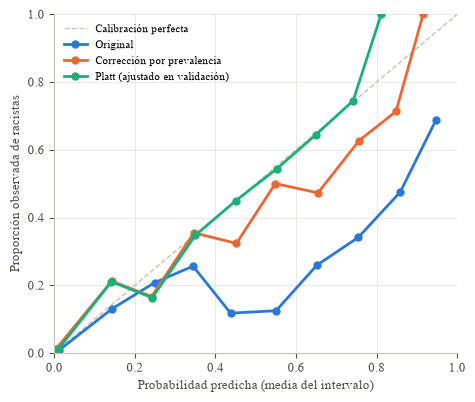

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
PI, PI_S = y_tr.mean(), np.mean(datos["train_y"])
def corregir_prevalencia(p):
    o = p / (1 - p) * (PI / (1 - PI)) / (PI_S / (1 - PI_S))
    return o / (1 + o)
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / np.clip(1 - p, 1e-7, 1 - 1e-7))
with np.errstate(all="ignore"):                                    # evita avisos espurios de matmul en macOS
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(val_final)[:, None], y_va)
def ece(y, p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1)
    return sum(abs(p[b == k].mean() - y[b == k].mean()) * (b == k).mean() for k in range(bins) if (b == k).any())

versiones = {"original": test_final, "corrección por prevalencia": corregir_prevalencia(test_final),
             "Platt (ajustado en validación)": platt.predict_proba(logit(test_final)[:, None])[:, 1]}
calib = pd.DataFrame({n: {"ECE": ece(y_te, p), "Brier": brier_score_loss(y_te, p), "probabilidad media": p.mean(),
                          "prevalencia real": y_te.mean(), "% con probabilidad ≥ 0.5": 100 * (p >= 0.5).mean(),
                          "% de racistas entre los de probabilidad ≥ 0.9": 100 * y_te[p >= 0.9].mean() if (p >= 0.9).any() else np.nan}
                      for n, p in versiones.items()}).T
calib.to_csv(SALIDAS / "calibracion.csv")
print(calib.round(4).to_string())

COLORES = {"original": "#2a78d6", "corrección por prevalencia": "#eb6834", "Platt (ajustado en validación)": "#1baf7a"}
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, linestyle="--", label="Calibración perfecta")
for n, p in versiones.items():
    fr, pm = calibration_curve(y_te, p, n_bins=10, strategy="uniform")
    ax.plot(pm, fr, marker="o", markersize=5, linewidth=2, color=COLORES[n], label=n.capitalize())
ax.set_xlabel("Probabilidad predicha (media del intervalo)"); ax.set_ylabel("Proporción observada de racistas")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.spines[["top", "right"]].set_visible(False); ax.grid(color=REJILLA, linewidth=0.6); ax.set_axisbelow(True)
ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.savefig(SALIDAS / "fig_calibracion.png", dpi=200, bbox_inches="tight"); plt.show()

**Lectura.** El modelo original sobreestima la probabilidad de racismo: su media es 0.0665 frente a una prevalencia de 0.0434, el 5.6 % de los tuits supera 0.5 y, entre los que superan 0.9, solo el 68.8 % es racista. La causa es el submuestreo del entrenamiento: la corrección analítica por prevalencia, sin ajustar nada a los datos, baja el ECE de 0.0231 a 0.0140, y el escalado de Platt ajustado en validación, a 0.0028. Ninguna corrección cambia el orden de los tuits, así que la clasificación no cambia; solo la interpretación de la probabilidad. Los intervalos altos tienen pocos tuits, de modo que esos puntos del diagrama son menos precisos.

### 5. Entradas fuera del dominio de entrenamiento

Se usan dos tipos de entrada. (a) **Un dominio real distinto, con etiquetas:** el corpus del artículo (González-Jiménez & Benítez-Andrades, 2022), con tuits de otros países, otra anotación y 48.6 % de positivos, clasificados con el mismo umbral. (b) **Entradas artificiales** que el modelo nunca vio: otro idioma, emojis, texto sin sentido o solo marcas. Ante ellas, un modelo prudente no debería dar probabilidades extremas.

In [25]:
art = pd.read_csv(INSUMOS / "corpus_articulo.csv", sep=";")
txt_art, y_art = normalizacion_minima(art["text"].astype(str)), art["target"].to_numpy()
p_art = predecir_prob(txt_art.tolist())
confianza = lambda p: np.maximum(p, 1 - p).mean()
fuera = pd.DataFrame({"prueba local (8.1)": {**metricas(y_te, test_final, U), "confianza media": confianza(test_final), "prevalencia": y_te.mean()},
                      "corpus del artículo": {**metricas(y_art, p_art, U), "confianza media": confianza(p_art), "prevalencia": y_art.mean()}})
fuera.to_csv(SALIDAS / "fuera_de_dominio.csv")
print(f"Corpus del artículo: {len(art):,} tuits ({100 * y_art.mean():.1f} % racistas); umbral del modelo final = {U:.3f}")
print(fuera.astype(float).round(3).to_string())
print(f"\nUmbral que maximizaría el F1 de la clase racista en el corpus del artículo (solo como diagnóstico, elegido con sus etiquetas): {mejor_umbral(y_art, p_art):.3f}")

ARTIFICIALES = {
    "inglés, neutral": ["the weather is nice today and we are going to the beach", "my neighbours from bolivia invited us for dinner"],
    "inglés, racista": ["all immigrants are criminals and should go back to their country"],
    "portugués, neutral": ["hoje o tempo está bom e vamos à praia com a família"],
    "solo emojis": ["😂😂😂", "🔥🔥👏👏"],
    "sin sentido": ["asdkj qwe zxcvb", "lorem ipsum dolor sit amet"],
    "números y signos": ["1234567", "?!?! ..."],
    "solo marcas": ["usuario url", "usuario usuario usuario"],
}
filas = [{"tipo": t, "texto": x} for t, xs in ARTIFICIALES.items() for x in xs]
artificiales = pd.DataFrame(filas); artificiales["probabilidad"] = predecir_prob(artificiales["texto"].tolist())
artificiales["predice racista"] = artificiales["probabilidad"] >= U
artificiales.to_csv(SALIDAS / "entradas_artificiales.csv", index=False)
print("\n" + artificiales.round(3).to_string(index=False))

Corpus del artículo: 2,000 tuits (48.6 % racistas); umbral del modelo final = 0.703
                     prueba local (8.1)  corpus del artículo
F1 macro                          0.815                0.579
precisión (racista)               0.612                0.612
recall (racista)                  0.687                0.435
F1 (racista)                      0.647                0.508
PR-AUC                            0.656                0.612
TN                             7665.000              759.000
FP                              155.000              268.000
FN                              111.000              550.000
TP                              244.000              423.000
umbral                            0.703                0.703
confianza media                   0.975                0.859
prevalencia                       0.043                0.486

Umbral que maximizaría el F1 de la clase racista en el corpus del artículo (solo como diagnóstico, elegido con sus etiquet

**Lectura.** Fuera de su dominio, el modelo se degrada. En el corpus del artículo (otros países, otra anotación y 48.6 % de racistas), el F1 macro cae de 0.815 a 0.579 y el recall de 0.687 a 0.435, con la misma precisión (0.612). Su confianza media baja de 0.975 a 0.859, pero sigue siendo alta para un modelo que omite más de la mitad de los racistas, y el umbral que maximizaría el F1 en ese corpus sería 0.006: sus probabilidades no son comparables entre dominios. Ante entradas artificiales no inventa racismo: emojis, texto sin sentido, otros idiomas y las marcas solas reciben probabilidades bajas (de 0.007 a 0.138). Pero tampoco detecta el racismo en inglés (0.009): no transfiere a otro idioma.

**Conclusión de 8.3.** Las fallas tienen tres orígenes. **Modelo:** confunde la mención de un grupo con racismo, lo que causa la mayoría de los falsos positivos. **Datos:** en el entrenamiento, mencionar a un grupo está fuertemente asociado con la etiqueta, y hay etiquetas dudosas y casos ambiguos. **Planteamiento:** clasificar la respuesta sin la noticia deja fuera el contexto que explica la mitad de los falsos negativos. Además, las probabilidades están infladas por el submuestreo, aunque se corrigen con calibración, y el modelo no generaliza a otro dominio. Usado para moderar, sus errores serían asimétricos: los falsos positivos censurarían a quienes nombran o defienden a los migrantes, y los falsos negativos dejarían pasar el racismo implícito o que depende del contexto.

## **8.4. Dictamen sobre la profundidad**

Falta saber si la línea base comete los mismos errores que la auditoría encontró en BETO. Se aplican a la SVM lineal de 8.1, con su propio umbral elegido en validación, los mismos casos de prueba de 8.2 y el mismo corpus fuera de dominio de 8.3. Si la SVM también confunde la mención de un grupo con racismo, el atajo viene de los datos y no de la profundidad.

In [26]:
# Mismas pruebas para la línea base (TF-IDF + SVM lineal de 8.1, umbral elegido en validación)
puntaje_svm = lambda textos: svm.decision_function(vec.transform(normalizacion_minima(pd.Series(list(textos)))))

# (a) Casos de prueba de respuesta conocida
casos["SVM predice racista"] = puntaje_svm(casos["texto"]) >= u_svm
casos["SVM acierta"] = casos["SVM predice racista"].astype(int) == casos["esperado"]
comp_casos = casos.groupby("tipo").agg(n=("texto", "size"), esperado=("esperado", "first"),
                                       BETO_marca_racista=("predice racista", "mean"), SVM_marca_racista=("SVM predice racista", "mean"),
                                       BETO_aciertos=("acierta", "mean"), SVM_aciertos=("SVM acierta", "mean")).loc[orden_t]
comp_casos.iloc[:, 2:] *= 100
comp_casos.to_csv(SALIDAS / "dictamen_casos_beto_vs_svm.csv")
print(f"Umbrales: BETO {U:.3f} | SVM {u_svm:.3f}\n\n% de frases marcadas como racistas y % de aciertos por tipo")
print(comp_casos.round(1).to_string())
neutral = casos[casos.tipo == "mención neutral"]
print("\nMenciones neutrales marcadas como racistas (%), por nacionalidad")
print((100 * neutral.groupby("grupo")[["predice racista", "SVM predice racista"]].mean()).rename(columns={"predice racista": "BETO", "SVM predice racista": "SVM"}).loc[GRUPOS].round(0).T.to_string())

# (b) Fuera de dominio: corpus del artículo
s_art = puntaje_svm(txt_art)
comp_fuera = pd.DataFrame({"BETO, prueba local": metricas(y_te, test_final, U), "SVM, prueba local": metricas(y_te, test_svm, u_svm),
                           "BETO, corpus del artículo": metricas(y_art, p_art, U), "SVM, corpus del artículo": metricas(y_art, s_art, u_svm)})
comp_fuera.to_csv(SALIDAS / "dictamen_fuera_de_dominio_beto_vs_svm.csv")
print("\nDentro y fuera de dominio")
print(comp_fuera.astype(float).round(3).to_string())

Umbrales: BETO 0.703 | SVM 0.245

% de frases marcadas como racistas y % de aciertos por tipo
                                  n  esperado  BETO_marca_racista  SVM_marca_racista  BETO_aciertos  SVM_aciertos
tipo                                                                                                             
racismo explícito                21         1                95.2               57.1           95.2          57.1
mención neutral                  21         0                71.4                0.0           28.6         100.0
mención neutral con usuario/url  21         0                61.9                0.0           38.1         100.0
contradiscurso                   14         0                92.9               28.6            7.1          71.4
insulto sin grupo                 3         0                 0.0                0.0          100.0         100.0

Menciones neutrales marcadas como racistas (%), por nacionalidad
grupo  bolivianos  paraguayos  peruanos  v

**Lectura.** La línea base no tiene el atajo de BETO. Con los mismos datos de entrenamiento, la SVM no marca como racista ninguna mención neutral (0.0 %, frente al 71.4 % de BETO) y marca el 28.6 % del contradiscurso (frente al 92.9 %). El atajo, por lo tanto, no es inevitable con estos datos: es propio del modelo profundo. A cambio, la SVM detecta mucho menos racismo explícito (57.1 % frente a 95.2 %) y generaliza peor fuera de dominio: en el corpus del artículo su F1 macro es de 0.435 y su recall de 0.101, frente a 0.579 y 0.435 de BETO. En la prueba local, BETO detecta 244 de los 355 racistas en lugar de 177, con 155 falsos positivos en lugar de 103.

**Dictamen.** La arquitectura profunda **se justifica, pero de forma condicionada**. A favor: cumple el criterio fijado en la Fase 1, no omitir mensajes racistas, porque detecta más racismo en la prueba, reconoce casi todo el racismo explícito construido y generaliza mejor a otro corpus. En contra: la mejora en F1 macro es moderada (0.046) para un costo de inferencia unas 600 veces mayor, se entrenó con solo 9,900 tuits (16.7 % racistas), y la auditoría mostró que parte de su sensibilidad es un atajo que la línea base no tiene. Por eso, el modelo no debería moderar de forma automática: se justifica como apoyo a revisores humanos, con probabilidades calibradas y después de corregir el atajo (8.5).

## **8.5. Limitaciones y proyección**

**Limitaciones.**
- **Tamaño y representatividad del corpus:** el corpus es argentino, de un solo periodo (la pandemia) y de cinco medios; el entrenamiento tiene 9,900 tuits (16.7 % racistas) y los errores se concentran en pocas noticias (8.3).
- **Supuestos de la transferencia:** se supuso que BETO, preentrenado en español general, sirve para comentarios informales, y que basta con leer la respuesta sin la noticia; este segundo supuesto falla en la mitad de los falsos negativos revisados (8.3).
- **Riesgo de sobreajuste:** la pérdida de validación sube desde la segunda época (la parada temprana lo controla), pero el atajo de 8.2 es un sobreajuste a una correlación de los datos que la parada no evita.
- **Estabilidad:** se auditó una sola semilla, el umbral es inestable (recall de 0.544 a 0.659 según la semilla en la Fase 2), la prueba tiene 355 racistas y los casos de prueba son 80.
- **Generalización:** fuera de dominio el F1 macro cae a 0.579 y el modelo no detecta racismo en otro idioma (8.3).

**Proyección.** Clasificar la respuesta junto con la noticia (`context_tweet` + `text`), como proponen los autores del corpus; corregir el atajo con aumento de datos contrafactual (menciones neutrales y contradiscurso etiquetados como no racistas) y usar los casos de prueba como control; probar un modelo preentrenado con tuits en español y repetir la auditoría con varias semillas. Llevarlo a producción, cuestión propia de MLOps, exigiría versionar el modelo, los datos, el umbral y la calibración; monitorear la tasa de mensajes marcados, la calibración y los casos de prueba en cada versión; detectar la deriva del vocabulario y de las predicciones y reetiquetar periódicamente; y mantener la revisión humana que exige el dictamen de 8.4.